# RetailCast: 28-day retail sales forecasting

**Question:** what can we forecast using only information available at the start of a 28-day window?

This executed notebook examines a reproducible historical experiment. It is a research companion to the CLI, not a replacement for the auditable source modules. All reported scores are computed from saved predictions and checked below.

Data: Chen, D. (2012), [Online Retail II, UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii), CC BY 4.0. Observed sales are not unconstrained demand. No production savings or current-date forecasts are claimed.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src/retailcast').exists(), 'Run from the repository or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from retailcast.config import Config
from retailcast.data import load_panel, sha256
from retailcast.features import make_design, origin_features, training_slice
from retailcast.models import forecast_models
from retailcast.evaluation import make_splits, metrics, select_models, conformal_radius

panel = load_panel(ROOT)
summary = json.loads((ROOT / 'reports/run_summary.json').read_text())
provenance = json.loads((ROOT / 'data/processed/provenance.json').read_text())
cfg = Config(**summary['config'])
assert sha256(ROOT / 'data/processed/daily_sales.csv') == summary['processed_sha256']
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.Series({'start': panel.index.min(), 'end': panel.index.max(), 'days': len(panel), 'markets': len(panel.columns), 'raw rows': provenance['raw_rows']}))
panel.head()

start       2009-12-01 00:00:00
end         2011-12-08 00:00:00
days                        738
markets                       5
raw rows                1067371
dtype: object

,United Kingdom,Netherlands,EIRE,Denmark,France
date,,,,,
2009-12-01,22696.0,0.0,737.0,0.0,654.0
2009-12-02,27267.0,3792.0,0.0,480.0,260.0
2009-12-03,48669.0,0.0,202.0,0.0,79.0
2009-12-04,19744.0,278.0,0.0,0.0,231.0
2009-12-05,4722.0,0.0,0.0,0.0,0.0


## 1. Target definition and data quality
Target: daily positive merchandise units, after removing cancellations, invalid quantities/prices and non-merchandise codes. Exact duplicate rows are treated as accidental duplicates; missing customer IDs are retained. Large orders are not winsorized. The final partial day is excluded.

The audit counts are sequential, not overlapping. Zero-filled dates represent **zero observed sales**, and may hide incomplete reporting. The raw workbook transport and SHA-256 are recorded transparently in provenance.

In [2]:
audit = pd.read_csv(ROOT / 'data/processed/cleaning_audit.csv')
assert audit.removed.sum() + audit.iloc[-1].remaining == provenance['raw_rows']
assert panel.index.is_unique and not panel.isna().any().any()
assert (panel >= 0).all().all()
display(audit)
print('Market selection used data through:', provenance['market_selection_end'])
print('Raw workbook SHA-256:', provenance['raw_sha256'])

,rule,removed,remaining
0,raw_rows,0,1067371
1,exact_duplicate_rows,34335,1033036
2,missing_or_nonfinite_required,0,1033036
3,cancellation_invoices,19104,1013932
4,nonpositive_units_or_price,6019,1007913
5,nonmerchandise_codes,4700,1003213
6,incomplete_final_day,1611,1001602


Market selection used data through: 2011-05-26
Raw workbook SHA-256: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980


## 2. Temporal protocol fixed before model selection
Four consecutive validation windows select per-market champions. Two later windows provide interval calibration errors. Only the final window is the reported holdout. Expanding refits may include observations from previous windows once they are in the past.

Top markets and exploratory seasonal profiles use the initial training period, not the test period.

,fold,stage,cutoff_index,train_end,test_start,test_end
0,1,validation,542,2011-05-26,2011-05-27,2011-06-23
1,2,validation,570,2011-06-23,2011-06-24,2011-07-21
2,3,validation,598,2011-07-21,2011-07-22,2011-08-18
3,4,validation,626,2011-08-18,2011-08-19,2011-09-15
4,5,calibration,654,2011-09-15,2011-09-16,2011-10-13
5,6,calibration,682,2011-10-13,2011-10-14,2011-11-10
6,7,holdout,710,2011-11-10,2011-11-11,2011-12-08


,train_mean_units,train_zero_share,train_max_units
United Kingdom,11559.662362,0.193727,118537.0
Netherlands,485.673432,0.787823,14552.0
EIRE,426.968635,0.579336,26016.0
Denmark,426.431734,0.952030,83774.0
France,367.062731,0.608856,87542.0


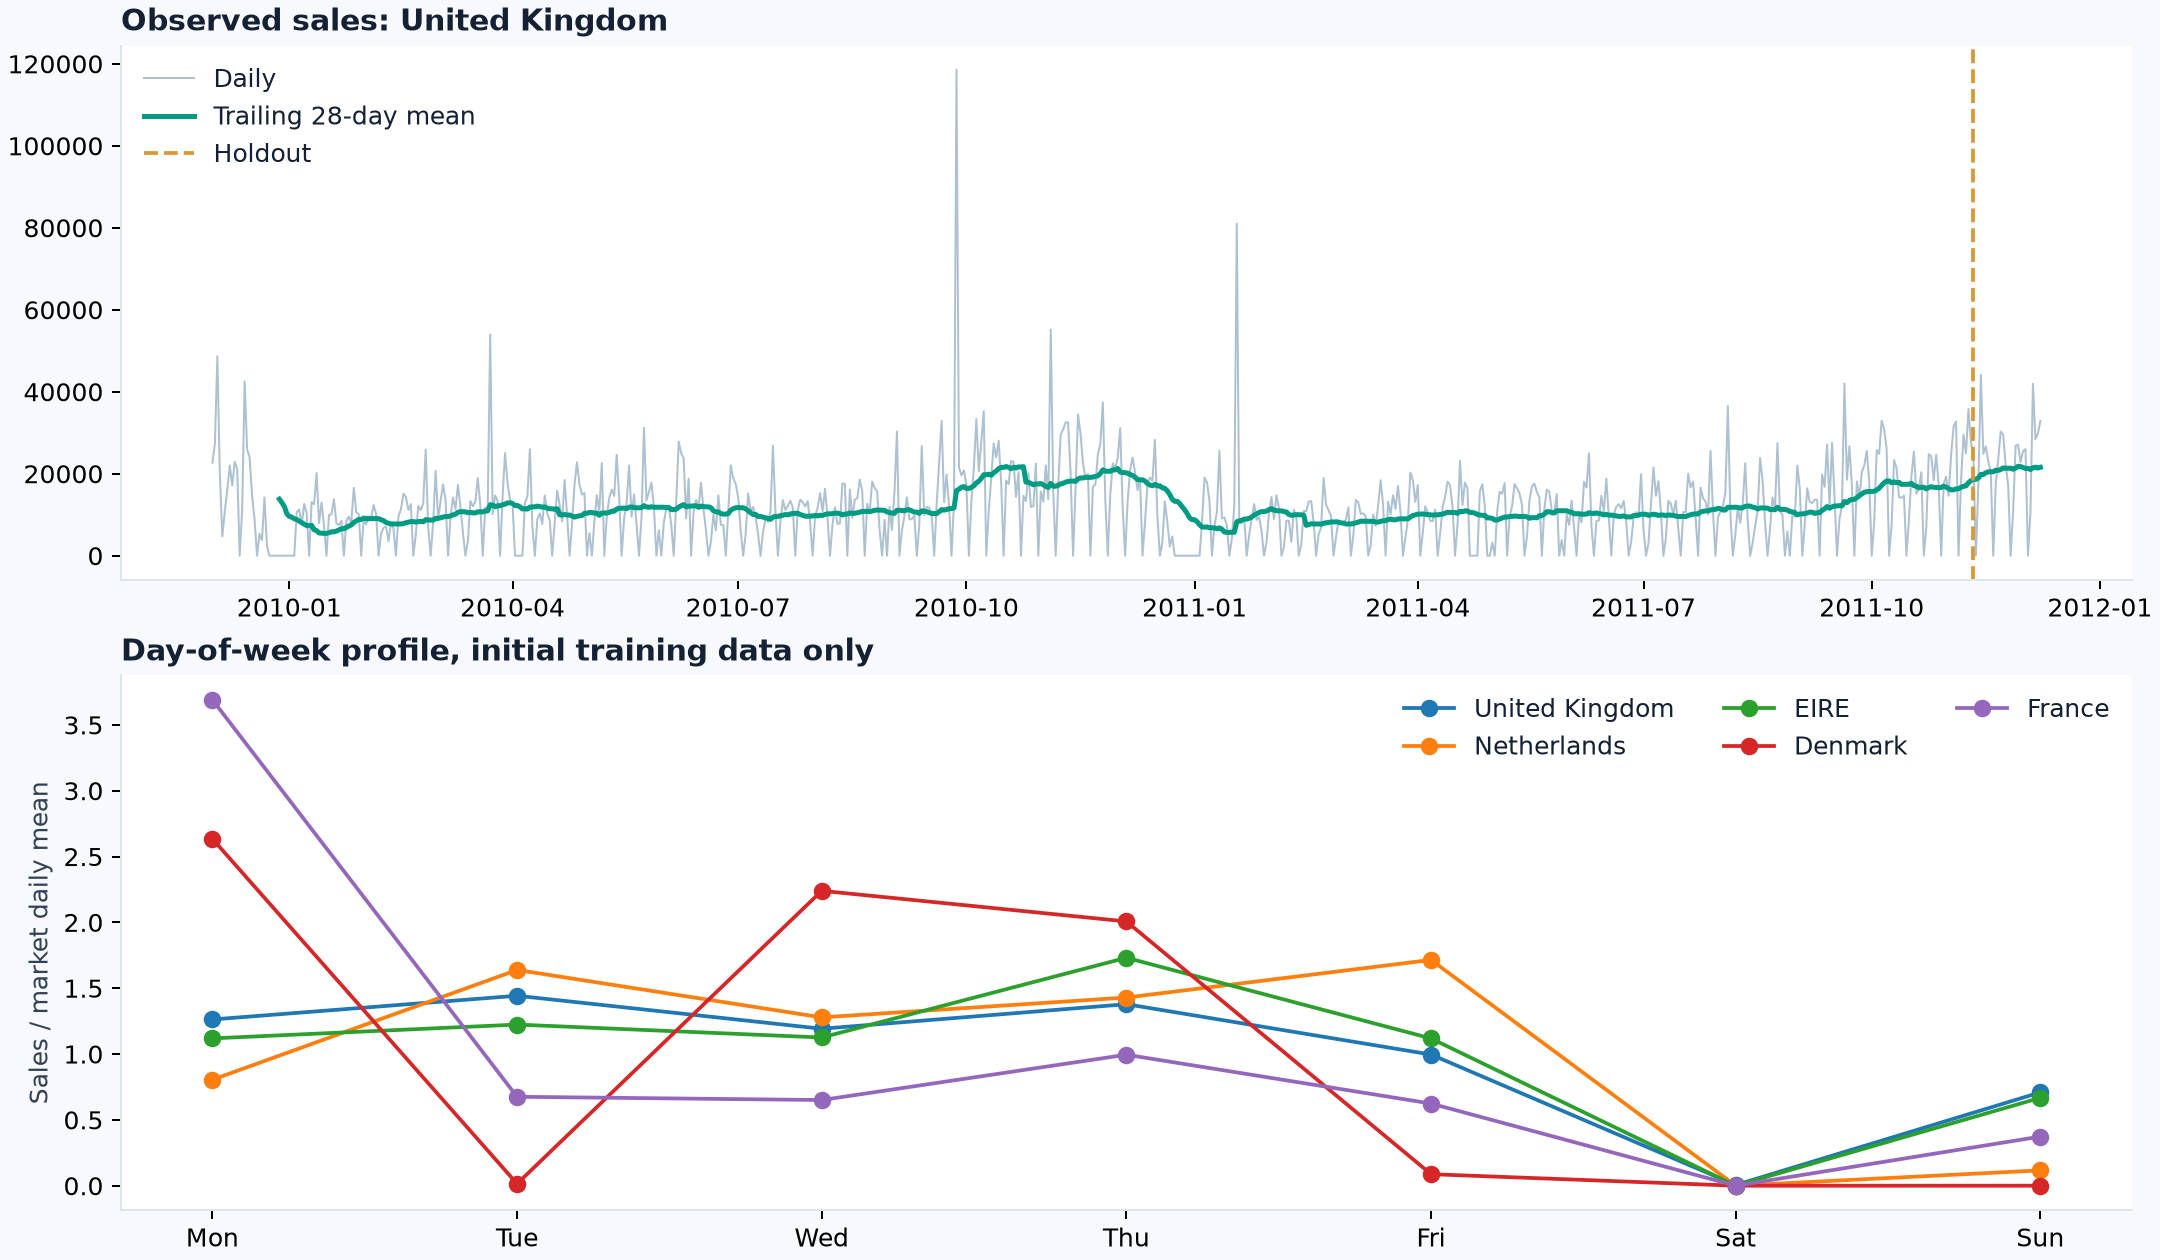

In [3]:
splits = pd.DataFrame(make_splits(panel, cfg))
display(splits)
initial = panel.iloc[:int(splits.iloc[0].cutoff_index)]
display(pd.DataFrame({'train_mean_units': initial.mean(), 'train_zero_share': initial.eq(0).mean(), 'train_max_units': initial.max()}))
display(Image(filename=str(ROOT / 'reports/figures/data_overview.png')))

## 3. Seasonality and volatility in training only
An ACF and robust weekly STL decomposition help inspect recurring patterns. These are diagnostics, not a claim that the whole series is stationary. The model uses a weekly cycle and a historical 364-day anchor when it exists; two years are insufficient to establish stable annual seasonality.

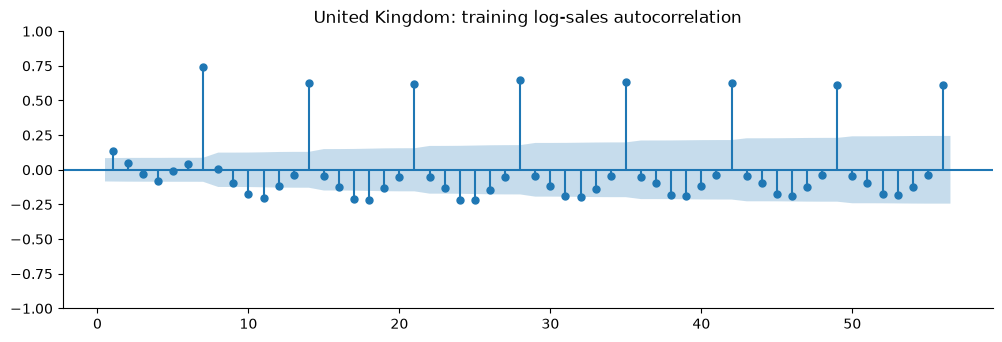

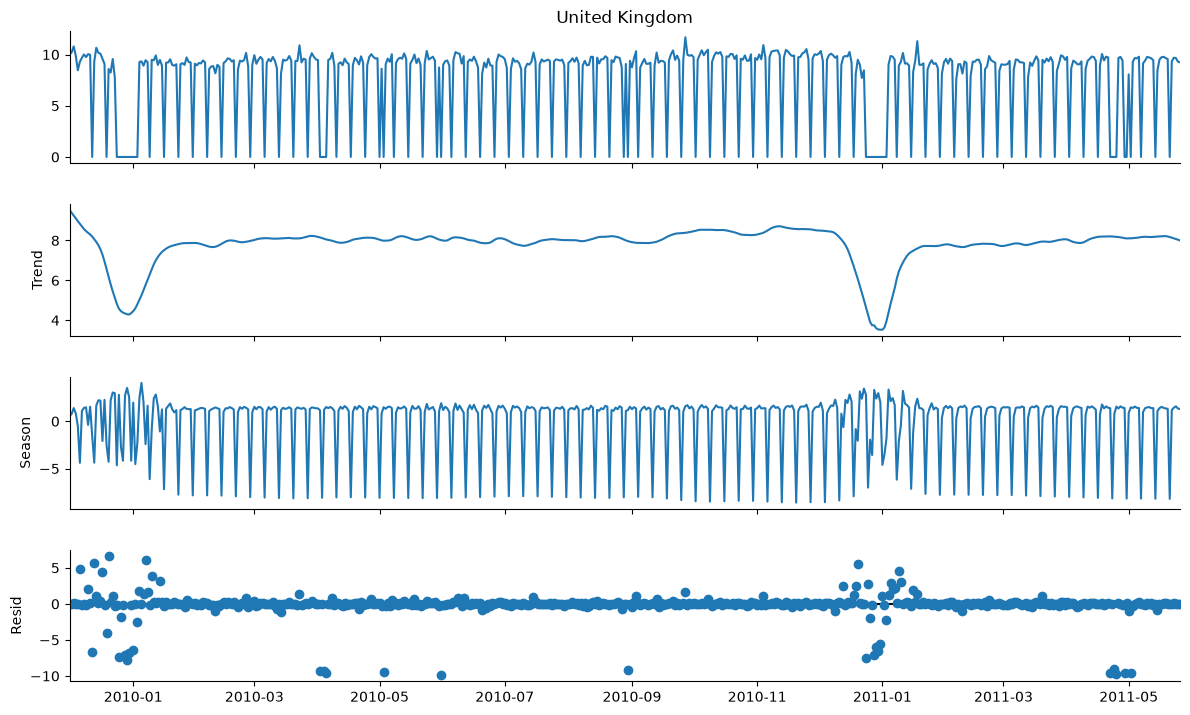

In [4]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL
market = panel.columns[0]
fig, ax = plt.subplots(figsize=(12, 3.6))
plot_acf(np.log1p(initial[market]), lags=56, ax=ax, zero=False)
ax.set_title(f'{market}: training log-sales autocorrelation')
plt.show()
decomposition = STL(np.log1p(initial[market]), period=7, robust=True).fit()
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()

## 4. Origin-safe direct forecasting
One global model receives a row per market/origin/horizon. Normalization and all lags/rolling statistics use only completed history. A horizon feature and known target calendar let one model distinguish 28 forecast dates.

For training, filtering historical origins is **insufficient**: their multi-step labels may cross the cutoff. The code below asserts that every included label is strictly in the past.

In [5]:
design, meta = make_design(panel, cfg)
cutoff = int(splits.iloc[0].cutoff_index)
train_x, train_y = training_slice(design, meta, cutoff)
assert (meta.loc[train_x.index, 'target_index'] < cutoff).all()
risky = meta.loc[(meta.origin_index < cutoff) & (meta.target_index >= cutoff)]
assert not train_x.index.isin(risky.index).any()
f, scale = origin_features(panel.iloc[:cutoff, 0], panel.index[cutoff], range(1, 29), 0, len(panel.columns))
assert f.origin_lag_1.nunique() == 1
assert f.mean_28.nunique() == 1
print(f'{len(design):,} rows, {design.shape[1]} features; {len(risky):,} future-label rows purged at first origin')
display(f[['horizon','origin_lag_1','mean_28','weekday_profile','year_anchor','target_month']].iloc[[0,6,13,20,27]])

12,310 rows, 42 features; 290 future-label rows purged at first origin


,horizon,origin_lag_1,mean_28,weekday_profile,year_anchor,target_month
0,1,1.008182,1.029654,1.044308,1.190591,5
6,7,1.008182,1.029654,1.361882,1.209641,6
13,14,1.008182,1.029654,1.361882,0.897829,6
20,21,1.008182,1.029654,1.361882,1.123076,6
27,28,1.008182,1.029654,1.361882,0.742268,6


## 5. Reproduce one model / one validation fold
This cell actually refits the shallow GBM, using the first validation cutoff, and reconciles its predictions against the published artifacts. Random internal early stopping is disabled. Full experiment reproduction: `retailcast run`.

In [6]:
reproduced, _ = forecast_models(panel, cutoff, design, meta, cfg, ['gbm_shallow'])
cv = pd.read_csv(ROOT / 'reports/validation_predictions.csv', parse_dates=['date'])
reference = cv.loc[(cv.fold == 1) & (cv.model == 'gbm_shallow')]
check = reproduced.merge(reference[['market','date','prediction']], on=['market','date'], suffixes=('_rerun','_saved'), validate='one_to_one')
np.testing.assert_allclose(check.prediction_rerun, check.prediction_saved, rtol=1e-7, atol=1e-6)
print('Reproduced', len(check), 'validation predictions; values match saved experiment.')

Reproduced 140 validation predictions; values match saved experiment.


## 6. Candidate comparison and locked selection
Compare weekly naive, an 8-week weekday mean, damped weekly ETS, Ridge and two predefined GBM capacities. Select the smallest mean validation MASE separately for each market. Baselines remain eligible.

MASE is scale-normalized across markets. Original-unit WAPE answers a different question and is dominated by the largest market. MASE<1 does not itself establish a win against the held-out seasonal naive predictions.

,model,MAE,RMSE,WAPE,MASE,bias_pct
0,gbm_deep,1147.645369,2789.219642,0.471399,0.588906,-0.047754
1,weekday_mean_8w,1035.116518,2474.620256,0.425177,0.593577,-0.064724
2,gbm_shallow,1210.120394,3145.834778,0.497060,0.604430,-0.039866
3,ets_weekly,1111.040068,2491.255964,0.456363,0.678964,0.024039
4,seasonal_naive,1272.478571,3025.433197,0.522674,0.704959,-0.014900
5,ridge_direct,1712.308338,3504.270634,0.703336,0.856046,0.322584


model,ets_weekly,gbm_deep,gbm_shallow,ridge_direct,seasonal_naive,weekday_mean_8w
market,,,,,,
Denmark,0.269659,0.038852,0.043109,0.073733,0.054620,0.045745
EIRE,0.866476,0.838232,0.831995,0.973948,1.244535,0.878621
France,0.658371,0.452684,0.434092,0.848334,0.444190,0.453309
Netherlands,0.961692,0.869290,0.915001,1.255193,0.991129,0.968151
United Kingdom,0.638623,0.745472,0.797955,1.129023,0.790319,0.622059


Locked selection: {'Denmark': 'gbm_deep', 'EIRE': 'gbm_shallow', 'France': 'gbm_shallow', 'Netherlands': 'gbm_deep', 'United Kingdom': 'weekday_mean_8w'}


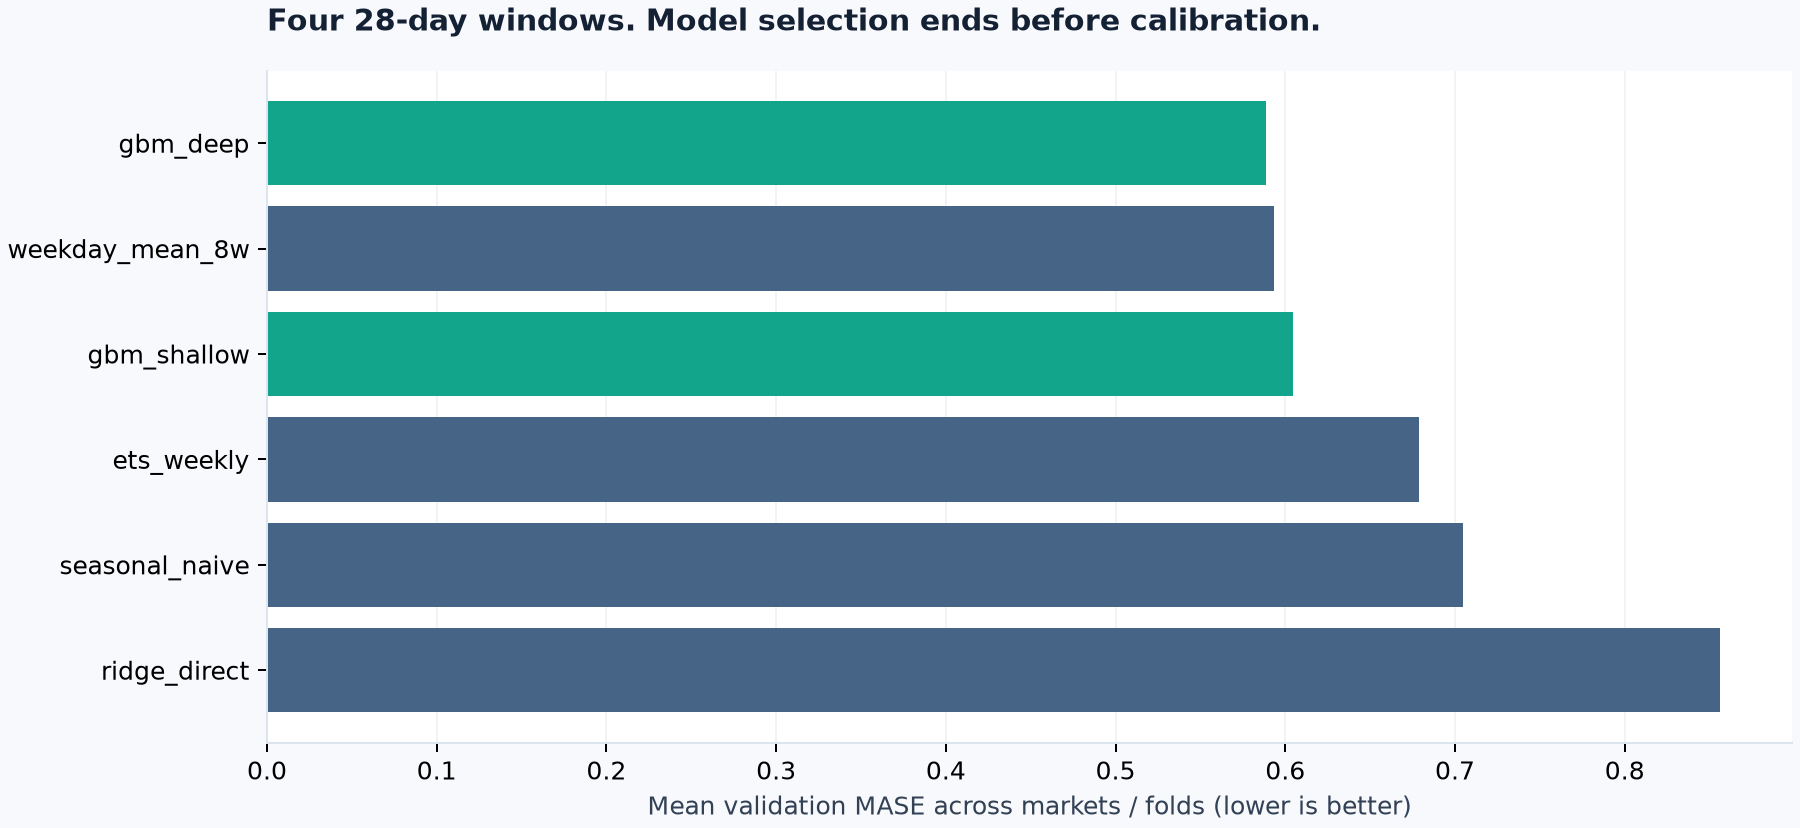

In [7]:
display(pd.read_csv(ROOT / 'reports/validation_leaderboard.csv'))
display(pd.read_csv(ROOT / 'reports/validation_by_market.csv').pivot(index='market', columns='model', values='MASE'))
locked = json.loads((ROOT / 'reports/locked_selection.json').read_text())
assert select_models(cv) == locked['selection'] == summary['selection']
print('Locked selection:', locked['selection'])
display(Image(filename=str(ROOT / 'reports/figures/validation_leaderboard.png')))

## 7. Holdout performance: outcomes after choices are frozen
Report the selected strategy alongside both seasonal baselines. A single peak-season holdout is narrow evidence, so inspect each market, bias and large misses. There is no post-test choice of winner in this notebook.

,MAE,RMSE,WAPE,MASE,bias_pct
model,,,,,
selected_champion,1246.429635,3285.374061,0.266319,0.645159,-0.172668
weekday_mean_8w,1334.880357,3359.130890,0.285218,0.745638,-0.157298
seasonal_naive,1659.064286,3660.774330,0.354485,0.867260,0.110348


,market,model,MAE,RMSE,WAPE,MASE,bias_pct
0,Netherlands,selected_champion,1039.439727,2009.866668,1.808845,1.099061,0.096523
1,Denmark,selected_champion,73.033023,210.966169,1.196562,0.109324,-0.711922
2,EIRE,selected_champion,457.256155,745.805449,0.710419,0.658301,-0.282407
3,France,selected_champion,315.115701,456.782641,0.561668,0.558710,-0.292802
4,United Kingdom,selected_champion,4347.303571,7008.528140,0.201631,0.800398,-0.171914
5,United Kingdom,weekday_mean_8w,4347.303571,7008.528140,0.201631,0.800398,-0.171914
6,Netherlands,weekday_mean_8w,1370.651786,2511.853565,2.385224,1.449271,0.520137
7,EIRE,weekday_mean_8w,576.723214,880.117034,0.896030,0.830295,-0.238847
8,Denmark,weekday_mean_8w,90.660714,211.851979,1.485372,0.135711,-0.279988
9,France,weekday_mean_8w,289.062500,412.843088,0.515230,0.512517,-0.182571


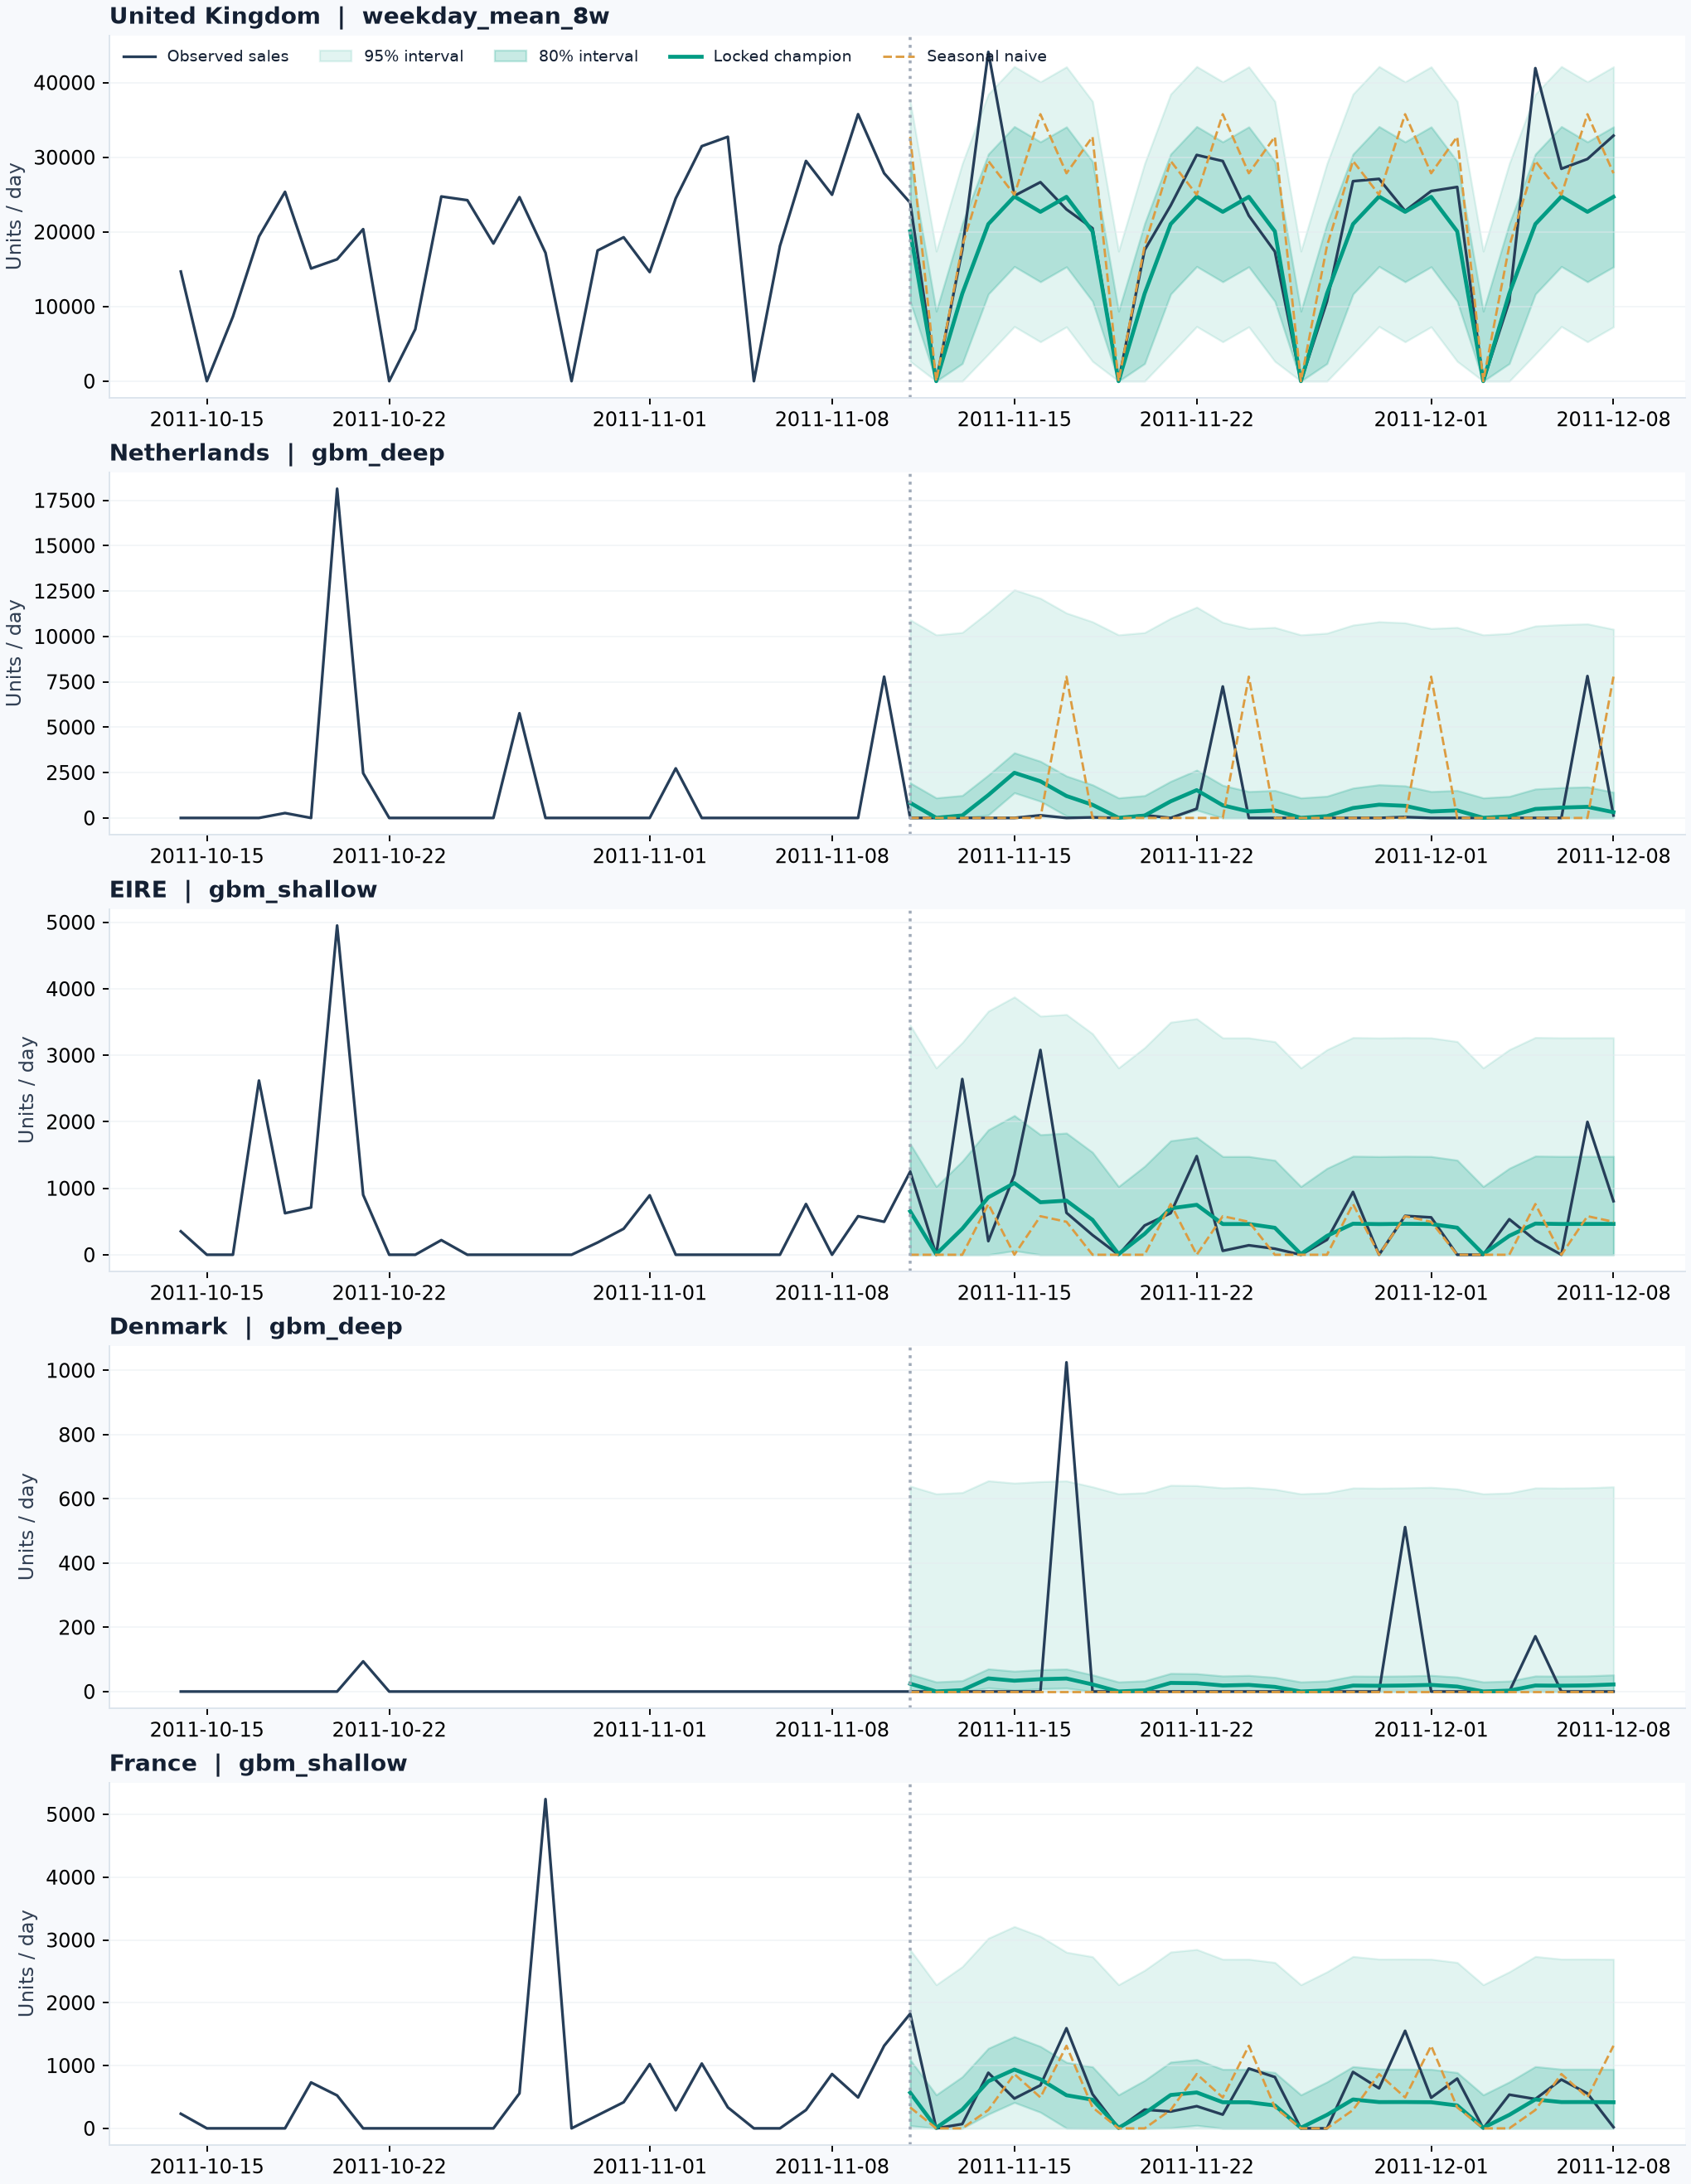

In [8]:
holdout = pd.read_csv(ROOT / 'reports/holdout_predictions.csv', parse_dates=['date'])
saved_scores = pd.read_csv(ROOT / 'reports/holdout_metrics.csv').set_index('model')
for model, g in holdout.groupby('model'):
    calculated = metrics(g)
    for key in ['MAE', 'RMSE', 'WAPE', 'MASE', 'bias_pct']:
        np.testing.assert_allclose(calculated[key], saved_scores.loc[model, key], rtol=1e-10)
display(saved_scores)
display(pd.read_csv(ROOT / 'reports/holdout_by_market.csv'))
display(Image(filename=str(ROOT / 'reports/figures/holdout_forecasts.png')))

## 8. Uncertainty: calibrated empirically, not guaranteed
Pool 56 earlier absolute errors per market from two calibration windows. For coverage c, take sorted error rank ceil((n+1)c); this gives ranks 46 and 55 for 80% and 95%. No holdout residual enters that calculation. Temporal dependence and distribution shift invalidate an exchangeability-based guarantee.

Intervals are marginal daily intervals pooled across horizons; they are neither a simultaneous 28-day band nor a calibrated interval for the total.

,market,n,coverage_80,width_80,interval_score_80,coverage_95,width_95,interval_score_95
0,Denmark,28,0.785714,46.024347,605.231983,0.964286,632.857253,1160.273090
1,EIRE,28,0.892857,1475.725678,2557.347226,1.000000,3262.008116,3262.008116
2,France,28,0.857143,885.342687,1563.657786,1.000000,2674.264018,2674.264018
3,Netherlands,28,0.785714,1622.504936,6619.096394,1.000000,10712.481830,10712.481830
4,United Kingdom,28,0.928571,17411.410714,26415.160714,0.928571,31538.553571,44569.625000


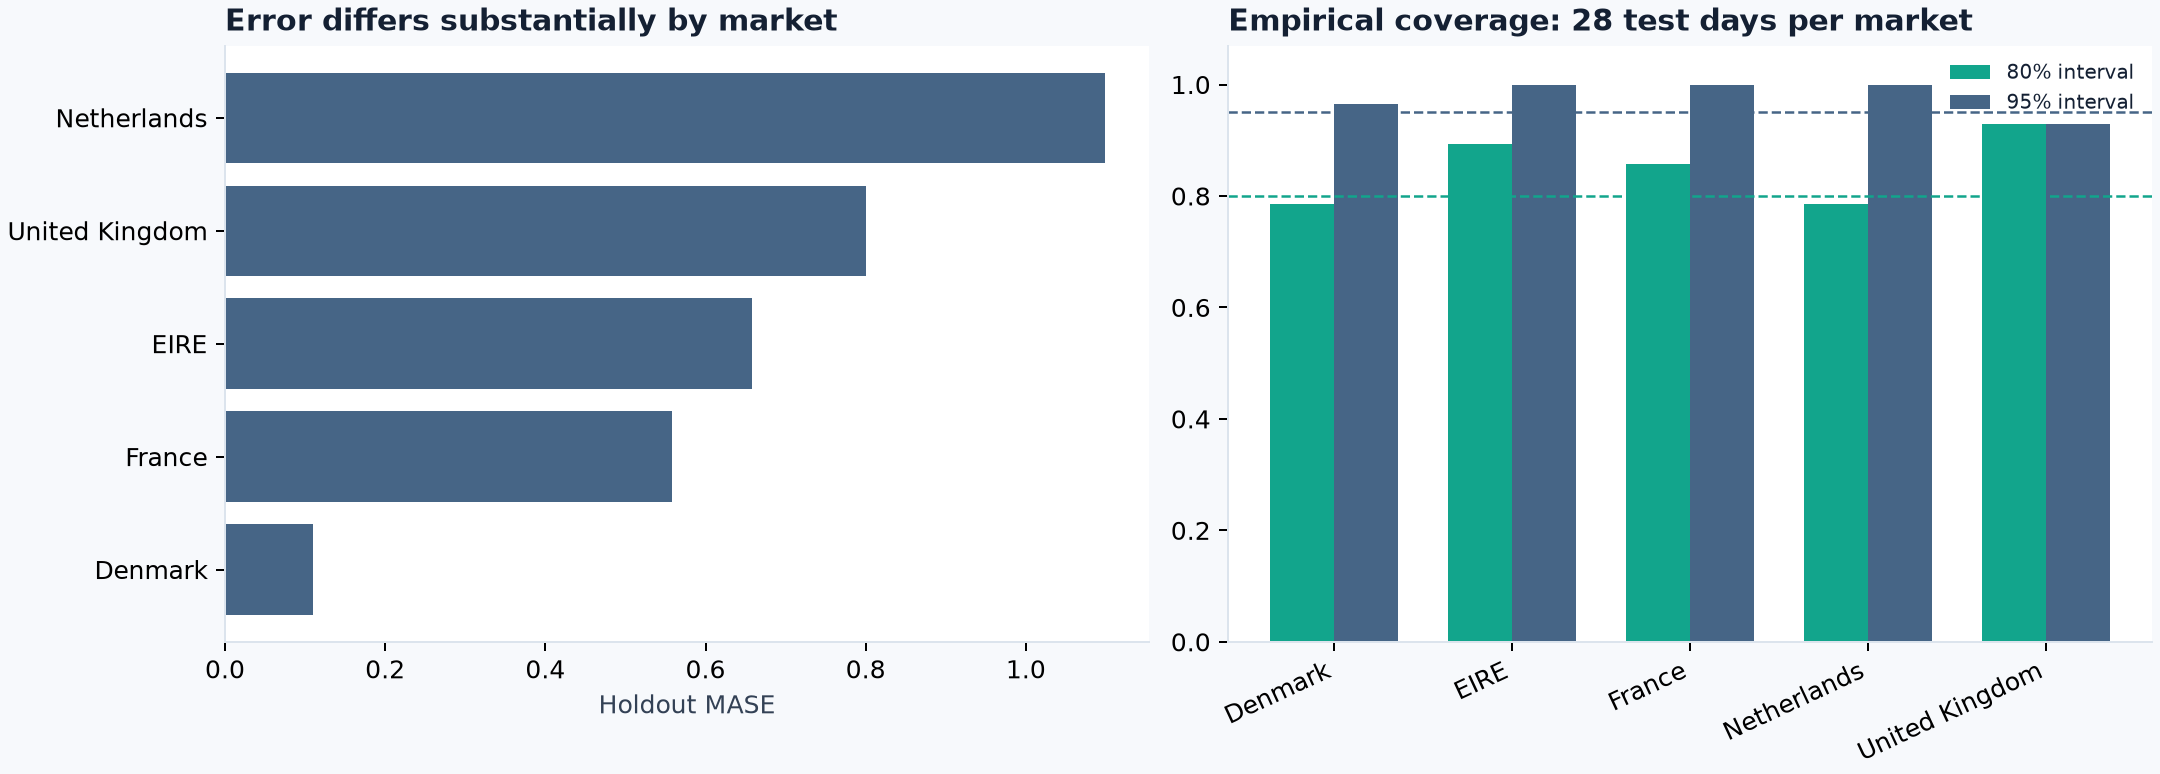

In [9]:
cal = pd.read_csv(ROOT / 'reports/calibration_predictions.csv', parse_dates=['date'])
radii = json.loads((ROOT / 'reports/interval_calibration.json').read_text())
assert cal.date.max() < holdout.date.min()
for market, g in cal.groupby('market'):
    assert len(g) == 56
    for level in [.8,.95]:
        np.testing.assert_allclose(conformal_radius(g.error, level), radii[market][str(level)])
display(pd.read_csv(ROOT / 'reports/interval_metrics.csv'))
display(Image(filename=str(ROOT / 'reports/figures/error_diagnostics.png')))

## 9. Failure analysis
Bias sign, large spikes, sparse markets and coverage misses determine practical usefulness. Do not delete large errors just because they hurt the score. Error patterns observed here are hypotheses for a future experiment, not authorization to tune this holdout.

,week_ahead,MAE,RMSE,WAPE,MASE,bias_pct
0,1,1623.406665,4237.350810,0.323110,0.903142,-0.194858
1,2,1044.645761,2208.048721,0.232635,0.565500,-0.139004
2,3,576.327914,1216.235971,0.146605,0.367122,-0.035199
3,4,1741.338202,4343.371949,0.330120,0.744871,-0.282642


,market,date,selected_model,actual,prediction,error
0,United Kingdom,2011-11-14,weekday_mean_8w,44115.0,21046.375000,-23068.625000
1,United Kingdom,2011-12-05,weekday_mean_8w,41939.0,21046.375000,-20892.625000
2,United Kingdom,2011-12-08,weekday_mean_8w,32895.0,24697.125000,-8197.875000
3,Netherlands,2011-12-07,gbm_deep,7818.0,611.017782,-7206.982218
4,United Kingdom,2011-12-07,weekday_mean_8w,29764.0,22687.125000,-7076.875000
5,United Kingdom,2011-11-23,weekday_mean_8w,29491.0,22687.125000,-6803.875000
6,Netherlands,2011-11-23,gbm_deep,7244.0,695.594672,-6548.405328
7,United Kingdom,2011-12-02,weekday_mean_8w,26017.0,20073.000000,-5944.000000
8,United Kingdom,2011-11-13,weekday_mean_8w,17597.0,11732.875000,-5864.125000
9,United Kingdom,2011-11-20,weekday_mean_8w,17558.0,11732.875000,-5825.125000


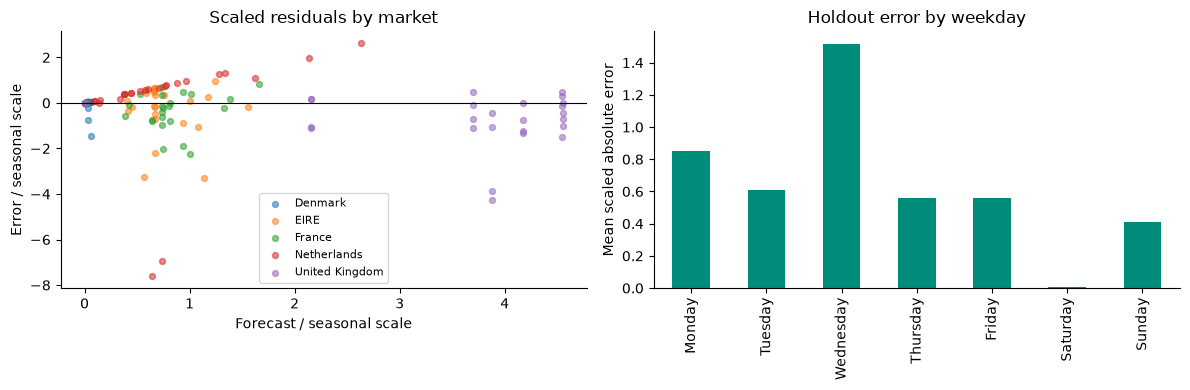

In [10]:
display(pd.read_csv(ROOT / 'reports/errors_by_horizon.csv'))
display(pd.read_csv(ROOT / 'reports/largest_errors.csv')[['market','date','selected_model','actual','prediction','error']].head(12))
champ = holdout.loc[holdout.model == 'selected_champion'].copy()
fig, axes = plt.subplots(1,2,figsize=(12,4))
for market, g in champ.groupby('market'):
    axes[0].scatter(g.prediction / g.mase_scale, g.error / g.mase_scale, alpha=.55, label=market, s=18)
axes[0].axhline(0,color='black',linewidth=.8)
axes[0].set(xlabel='Forecast / seasonal scale',ylabel='Error / seasonal scale',title='Scaled residuals by market')
axes[0].legend(fontsize=8)
champ.assign(weekday=champ.date.dt.day_name()).groupby('weekday').scaled_abs_error.mean().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']).plot.bar(ax=axes[1],color='#008c7a')
axes[1].set(ylabel='Mean scaled absolute error',title='Holdout error by weekday',xlabel='')
plt.tight_layout()
plt.show()

## 10. Historical continuation and next experiment
Refit the locked algorithms on the full panel and predict the next 28 dates after the historical endpoint. These outcomes are unavailable. This is not a current-date forecast; Christmas shutdowns and changing sales levels can make old calibration radii stale.

The next experiment should first obtain stock availability, price/promotion plans and calendar completeness. Add longer seasonal validation and only then test richer model classes or SKU hierarchy. Inventory-policy benefits require actual lead times and business costs.

In [11]:
future = pd.read_csv(ROOT / 'reports/forecast_28d.csv', parse_dates=['date'])
assert future.date.min() > panel.index.max()
assert future.groupby('market').size().eq(28).all()
display(future.groupby('market').agg(forecast_total_units=('prediction','sum'),first_date=('date','min'),last_date=('date','max')))
print(summary['warning'])

,forecast_total_units,first_date,last_date
market,,,
Denmark,319.788613,2011-12-09,2012-01-05
EIRE,8055.554012,2011-12-09,2012-01-05
France,7570.405384,2011-12-09,2012-01-05
Netherlands,9207.864475,2011-12-09,2012-01-05
United Kingdom,558068.500000,2011-12-09,2012-01-05


Historical continuation only. Intervals use 56 earlier errors/market; temporal dependence and seasonality shifts invalidate exchangeability guarantees.
